# deps

In [1]:
# get the version of the package use

import sys

import math

import matplotlib
import matplotlib.pyplot as pyplot
import pandas
import scipy

print("python     :", sys.version.split(' ')[0])
for module in (matplotlib, pandas, scipy):
    print(f"{module.__name__:<11}:", module.__version__)

python     : 3.13.5
matplotlib : 3.11.2
pandas     : 3.1.1
scipy      : 1.18.1


# Constant

In [2]:
DATA_PATH = "../data"
CSV_CLEAN = "boardGamesClean.csv"

#column name
TITLE = "Title"

ORIGINAL_TYPE = "Type 1"
TYPE = "Type"

COMPLEXITY = "Complexity"

MEAN_TIME = "Mean time"

ORIGINAL_AVERAGE_RATING = "Avg rating"
AVERAGE_RATING = "Average rating"

ORIGINAL_NUMBER_VOTE = "Num of voters"
NUMBER_VOTE = "Number of voters"

POPULARITY = "Popularity"

# Loading data

In [3]:
print(f"{DATA_PATH}/{CSV_CLEAN}")
cleanDataFrame = pandas.read_csv(f"{DATA_PATH}/{CSV_CLEAN}")
cleanDataFrame = cleanDataFrame.rename(columns={
    ORIGINAL_TYPE: TYPE,
    ORIGINAL_AVERAGE_RATING: AVERAGE_RATING,
    ORIGINAL_NUMBER_VOTE: NUMBER_VOTE
})

../data/boardGamesClean.csv


## Popularity

the popularity is calculate with

In [4]:
# caclculate the popularity
popularity = [(r/10)*100 * math.log10(val + 1) for r, val in zip(cleanDataFrame[AVERAGE_RATING], cleanDataFrame[NUMBER_VOTE])]

#insert the new column
cleanDataFrame.insert(1, POPULARITY, popularity, allow_duplicates=True)

In [5]:
# round all value to 2
cleanDataFrame = cleanDataFrame.round(2)

#sort
cleanDataFrame = cleanDataFrame.sort_values(by=POPULARITY, ascending=True).reset_index(drop=True)

# Get Global information

In [6]:
print("rows, columns:", cleanDataFrame.shape)
cleanDataFrame.info()
# show all rows
cleanDataFrame.head(cleanDataFrame.shape[0])

rows, columns: (9744, 11)
<class 'pandas.DataFrame'>
RangeIndex: 9744 entries, 0 to 9743
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Title             9744 non-null   str    
 1   Popularity        9744 non-null   float64
 2   Average rating    9744 non-null   float64
 3   Complexity        9744 non-null   float64
 4   Min time          9744 non-null   float64
 5   Max time          9744 non-null   float64
 6   Min players       9744 non-null   float64
 7   Max players       9744 non-null   float64
 8   Number of voters  9744 non-null   int64  
 9   Type              9744 non-null   str    
 10  Mean time         9744 non-null   float64
dtypes: float64(8), int64(1), str(2)
memory usage: 837.5 KB


,Title,Popularity,Average rating,Complexity,Min time,Max time,Min players,Max players,Number of voters,Type,Mean time
0,Feed the Woozle,111.07,5.42,1.00,15.0,15.0,2.0,5.0,111,Children's,15.0
1,Imperator,111.11,5.52,2.10,180.0,180.0,1.0,5.0,102,Strategy,180.0
2,Crash Pilot,111.48,5.43,1.13,20.0,20.0,2.0,5.0,112,Children's,20.0
3,Click Clack,111.62,5.50,1.00,20.0,20.0,2.0,4.0,106,Children's,20.0
4,Wabbit's Wevenge,111.77,5.53,1.55,120.0,120.0,2.0,4.0,104,Thematic,120.0
...,...,...,...,...,...,...,...,...,...,...,...
9739,Ark Nova,404.26,8.54,3.79,90.0,150.0,1.0,4.0,54162,Strategy,120.0
9740,Brass: Birmingham,405.53,8.58,3.87,60.0,120.0,2.0,4.0,53268,Strategy,90.0
9741,7 Wonders Duel,405.69,8.09,2.23,30.0,30.0,2.0,2.0,103444,Strategy,30.0
9742,Gloomhaven,412.18,8.56,3.92,60.0,120.0,1.0,4.0,65342,Strategy,90.0


In [7]:
# count = number of row fill with a value
# mean = mean of all the value
cross_table = pandas.pivot_table(
    cleanDataFrame,
    values=[AVERAGE_RATING, NUMBER_VOTE],
    index=[TYPE],
    aggfunc={"mean", "count"},
).round(2)

print(cross_table)

             Average rating       Number of voters         
                      count  mean            count     mean
Type                                                       
Abstract                709  6.53              709  1804.39
Children's              404  6.26              404   771.92
Customizable            246  6.86              246  1981.35
Family                 2801  6.59             2801  3050.67
Party                   561  6.51              561  3025.52
Strategy               2397  7.07             2397  3642.17
Thematic               1107  7.04             1107  2428.53
Wargames               1519  7.15             1519   461.19


## Graph

## generic function

In [8]:
#! function to show the evolution of a column by a graph

def evolutionGraph(rowName, dataFrame = cleanDataFrame, graphTitle=None):
    if graphTitle is None:
        graphTitle = f"evolution of {rowName}"

    # take the values of the column sort it and add it to the graph
    pyplot.plot(dataFrame[rowName].sort_values(ascending=True).reset_index(drop=True), color="b", marker=".", linestyle="none")

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel("Game Index")
    # set the label of the y axe
    pyplot.ylabel(rowName)
    # add a grib to the graph
    pyplot.grid(True)
    # show the graph
    pyplot.show()

In [9]:
#! function to make a boxplot of a column

def boxplot(rowName, dataFrame = cleanDataFrame, whis=(0, 100), graphTitle=None):
    # generate the title if is not provided
    if graphTitle is None:
        graphTitle = f"boxplot of {rowName}"

    #take the values of the column and make a boxplot
    pyplot.boxplot(dataFrame[rowName], whis=whis)

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel("Distribution")
    # set the label of the y axe
    pyplot.ylabel(rowName)
    # show the graph
    pyplot.grid(True)

    #  calculate all the quartile and the min/max value
    minVal = dataFrame[rowName].quantile(0)
    q1 = dataFrame[rowName].quantile(0.25)
    q2 = dataFrame[rowName].quantile(0.50)
    q3 = dataFrame[rowName].quantile(0.75)
    maxVal = dataFrame[rowName].quantile(1)
    iqr = q3 - q1;

    # create a string with all the stats
    statsText = (
        f"MAX: {maxVal:.2f}\n"
        f"Q3:  {q3:.2f}\n"
        f"Q2:  {q2:.2f}\n"
        f"Q1:  {q1:.2f}\n"
        f"MIN: {minVal:.2f}\n"
        f"IQR: {iqr:.2f}"
    )

    # display text on the graph
    pyplot.text(
        0.03, 0.05, statsText,
        # say to place the text relatively
        transform=pyplot.gca().transAxes,
        fontsize=9, 
        verticalalignment='bottom',
        horizontalalignment='left',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
    )

    

In [10]:
#! function to make a bar graph

def barGraph(rowName, valueColumn=None, dataFrame = cleanDataFrame, agg_func='mean', color="skyblue", graphTitle=None, showText=False, onConsole=True):
    # generate the title if is not provided
    if graphTitle is None:
        if valueColumn is None:
            graphTitle = f"Number of {rowName}"
        else:
            graphTitle = f"{agg_func.capitalize()} of {valueColumn} by {rowName}"

    # process data depending on whether a value column is specified
    if valueColumn is None:
        dataPlot = dataFrame[rowName].value_counts().sort_values()
        yLabel = f"Number of {rowName}"
    else:
        dataPlot = dataFrame.groupby(rowName)[valueColumn].agg(agg_func).sort_values()
        yLabel = f"{agg_func.capitalize()} of {valueColumn}"

    # Create the plot
    dataPlot.plot(kind="bar", color=color)

    # set title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel(rowName)
    # set the label of the y axe
    pyplot.ylabel(yLabel)
    # rotate the x values name
    pyplot.xticks(rotation=45, ha="right")
    
    # format data stats
    formattedLines = []

    # travel all items to get it's key and it's value
    for key, value in dataPlot.items():
        
        # check if is a float or not
        if isinstance(value, float):
            # round to 2
            line = f"{key}: {value:.2f}"
        else:
            line = f"{key}: {value}"
            
        # add the line to the list
        formattedLines.append(line)

    # join each part of the list with \n
    statsText = "\n".join(formattedLines)

    # show the stat
    if(showText):
        pyplot.text(
            0.03, 0.95, statsText,
            fontsize=8, 
            # say to place the text relatively
            transform=pyplot.gca().transAxes,
            verticalalignment='top',
            horizontalalignment='left',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
        )

    pyplot.tight_layout() 
    pyplot.show()

    if(onConsole):
        print(statsText)

## evolution graph

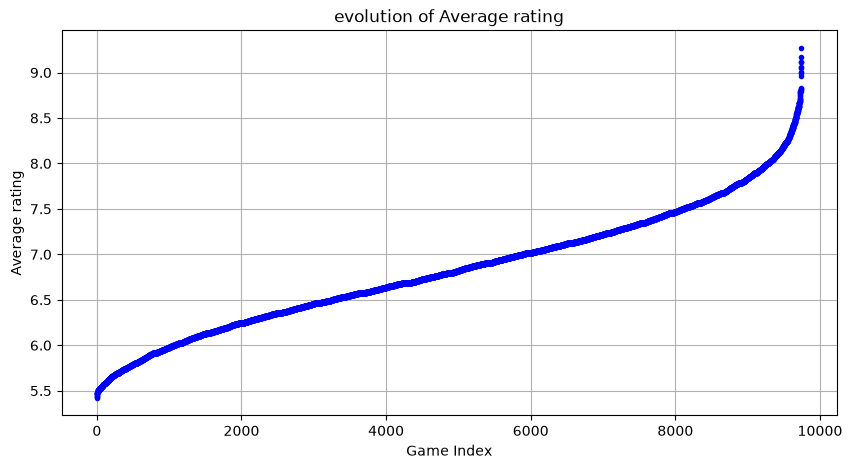

In [11]:
#! graph show the evolution of the average rating

# set the size of the graph
pyplot.figure(figsize=(10, 5))
evolutionGraph(AVERAGE_RATING)

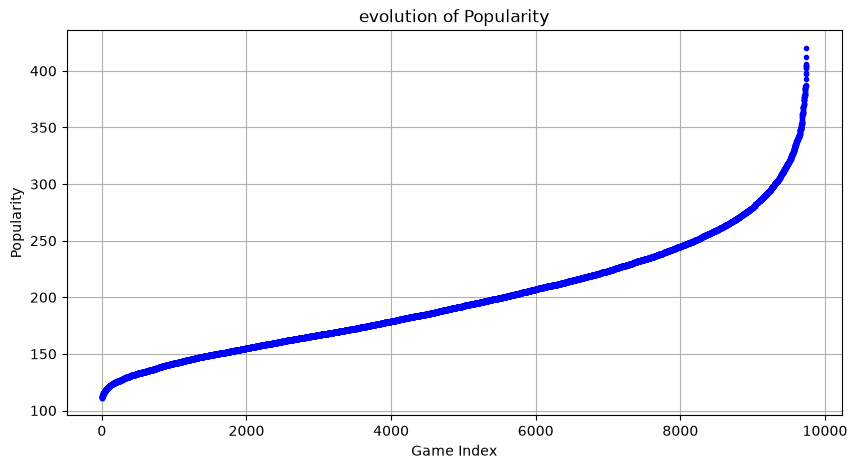

In [12]:
#! graph show the evolution of the popularity

# set the size of the graph
pyplot.figure(figsize=(10, 5))
evolutionGraph(POPULARITY)

## boxplot

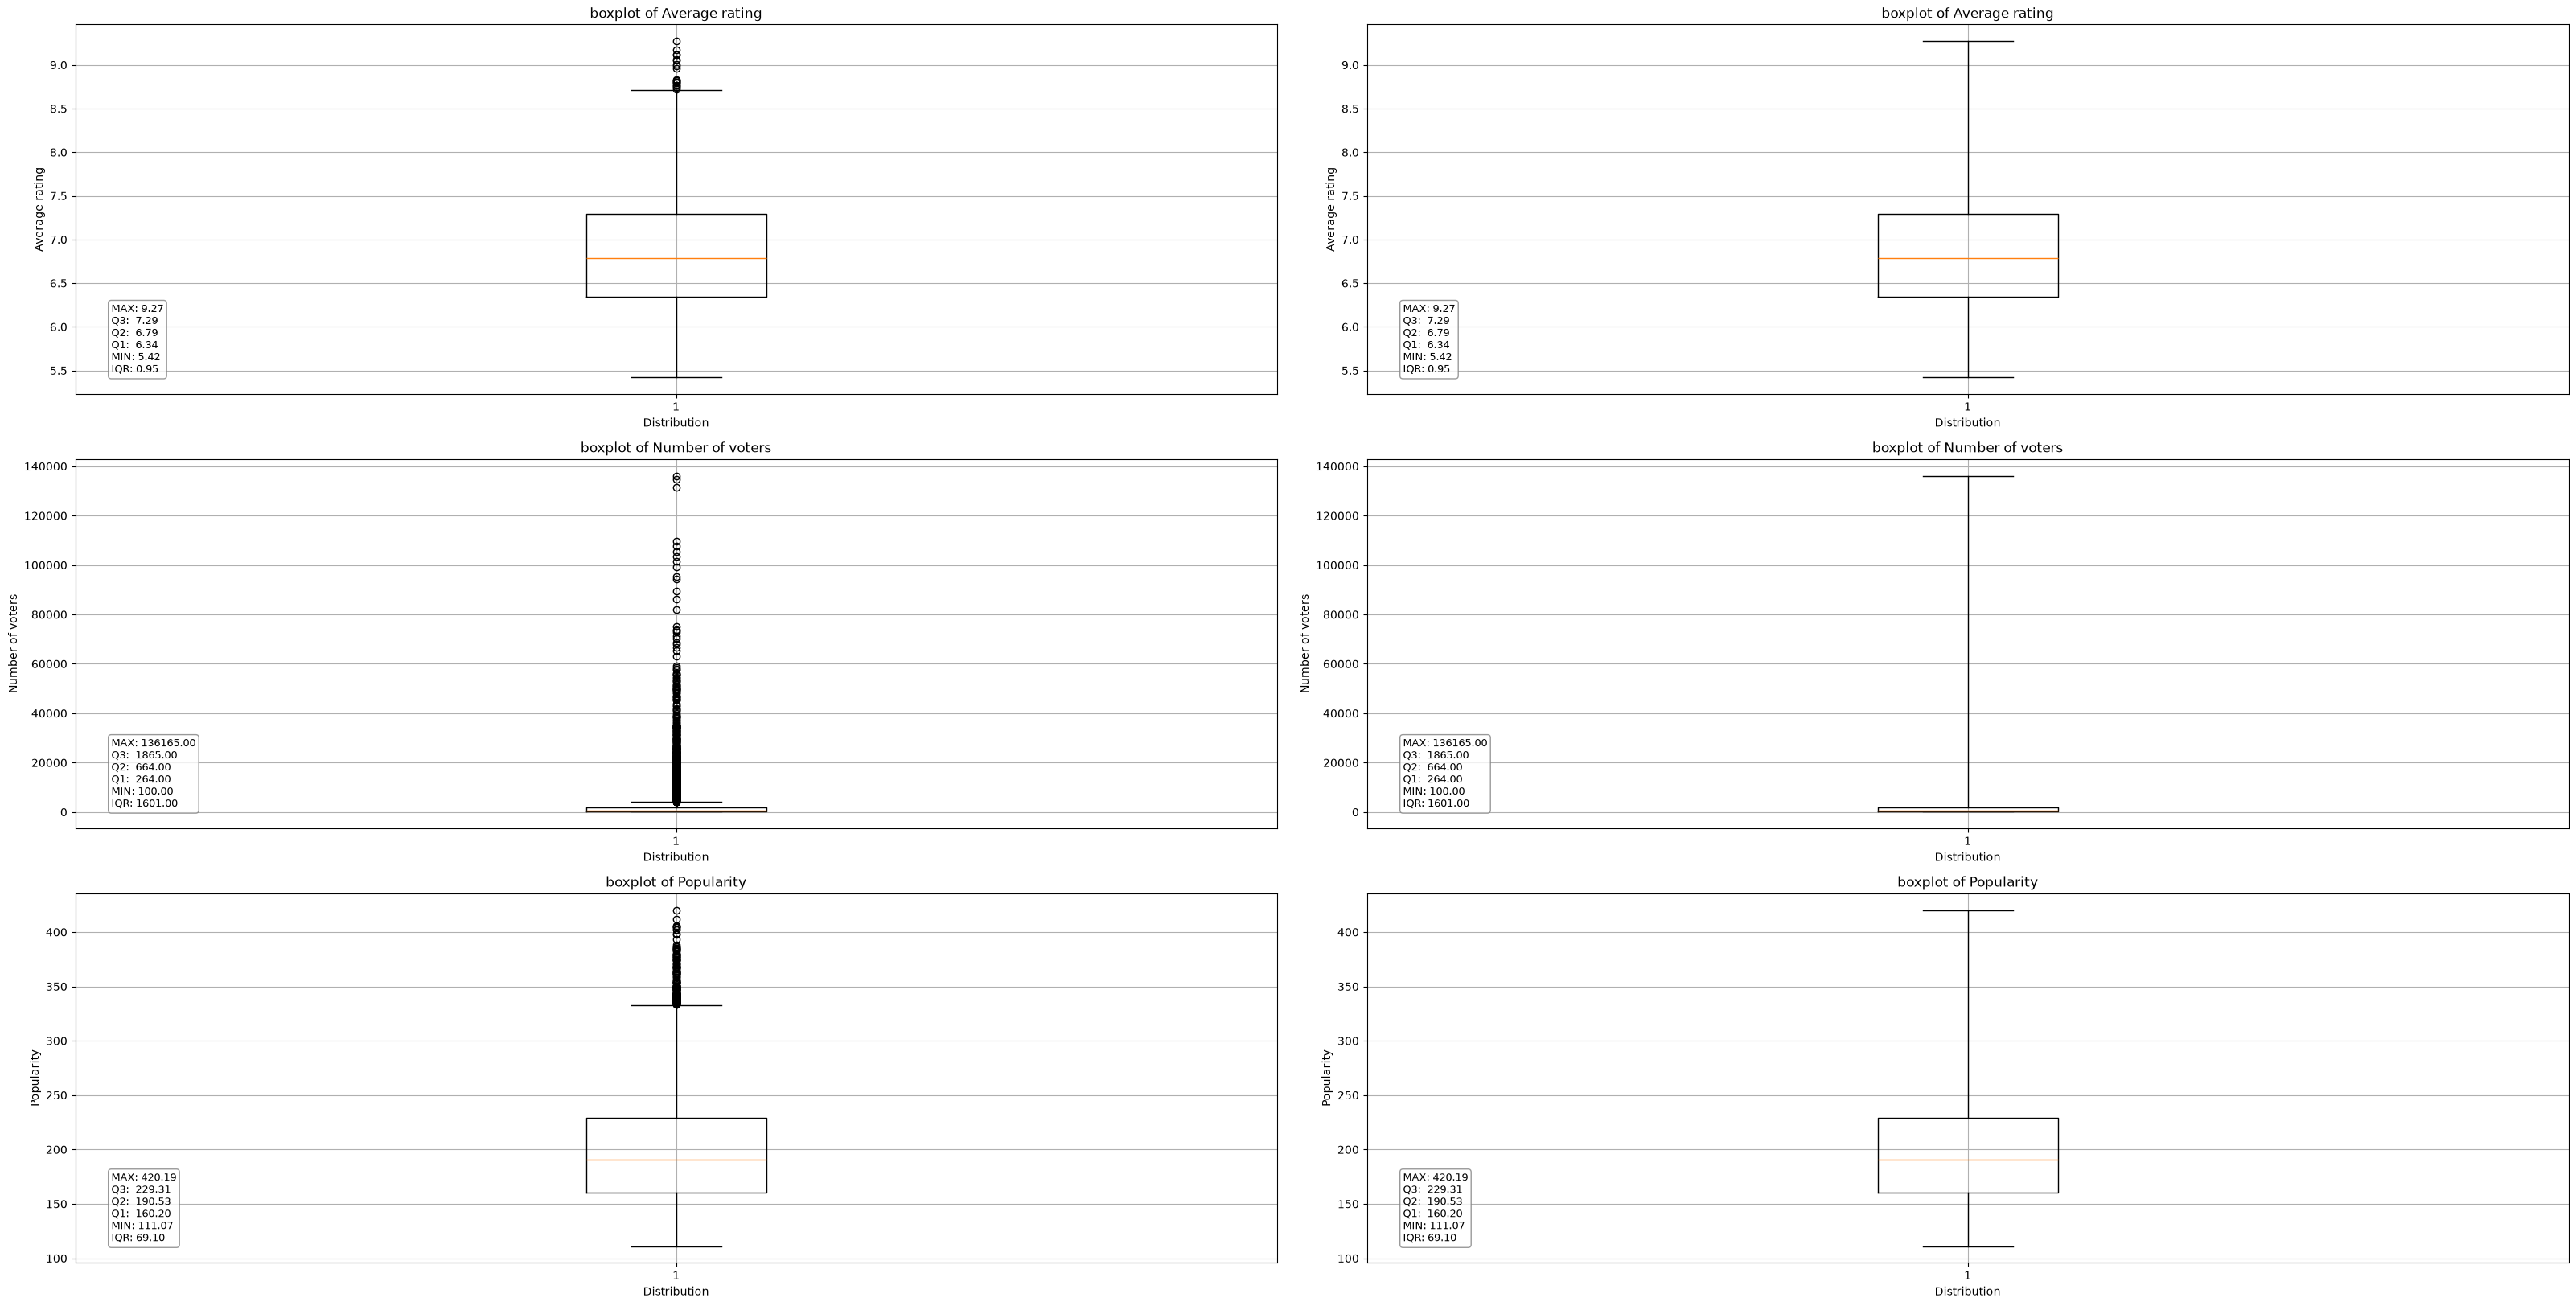

In [13]:
# graph show the evolution of the average rating
pyplot.figure(figsize=(40, 20))

pyplot.subplot(3, 2, 1)

boxplot(AVERAGE_RATING, whis=1.5)

pyplot.subplot(3, 2, 2)

boxplot(AVERAGE_RATING)

pyplot.subplot(3, 2, 3)

boxplot(NUMBER_VOTE, whis=1.5)

pyplot.subplot(3, 2, 4)

boxplot(NUMBER_VOTE)

pyplot.subplot(3, 2, 5)

boxplot(POPULARITY, whis=1.5)
pyplot.subplot(3, 2, 6)

boxplot(POPULARITY)

pyplot.subplots_adjust(wspace=0.075, hspace=0.175)
pyplot.show()

## number of value out of the box

In [14]:
# Liste des colonnes à analyser
columns_to_check = [AVERAGE_RATING, NUMBER_VOTE, POPULARITY]

for col in columns_to_check:
    # Calcul de Q1 (25e percentile) et Q3 (75e percentile)
    Q1 = cleanDataFrame[col].quantile(0.25)
    Q3 = cleanDataFrame[col].quantile(0.75)
    
    # Calcul de l'écart interquartile (IQR)
    IQR = Q3 - Q1
    
    # Seuils inférieur et supérieur
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Compter les valeurs en dessous et au-dessus des seuils
    count_lower_outliers = (cleanDataFrame[col] < lower_bound).sum()
    count_upper_outliers = (cleanDataFrame[col] > upper_bound).sum()
    
    print(f"--- {col} ---")
    print(f"  Valeurs < Q1 - 1.5*IQR (en dessous) : {count_lower_outliers} (Seuil : {lower_bound:.2f})")
    print(f"  Valeurs > Q3 + 1.5*IQR (au-dessus)  : {count_upper_outliers} (Seuil : {upper_bound:.2f})")

--- Average rating ---
  Valeurs < Q1 - 1.5*IQR (en dessous) : 0 (Seuil : 4.91)
  Valeurs > Q3 + 1.5*IQR (au-dessus)  : 20 (Seuil : 8.71)
--- Number of voters ---
  Valeurs < Q1 - 1.5*IQR (en dessous) : 0 (Seuil : -2137.50)
  Valeurs > Q3 + 1.5*IQR (au-dessus)  : 1165 (Seuil : 4266.50)
--- Popularity ---
  Valeurs < Q1 - 1.5*IQR (en dessous) : 0 (Seuil : 56.55)
  Valeurs > Q3 + 1.5*IQR (au-dessus)  : 159 (Seuil : 332.96)


## bar graph

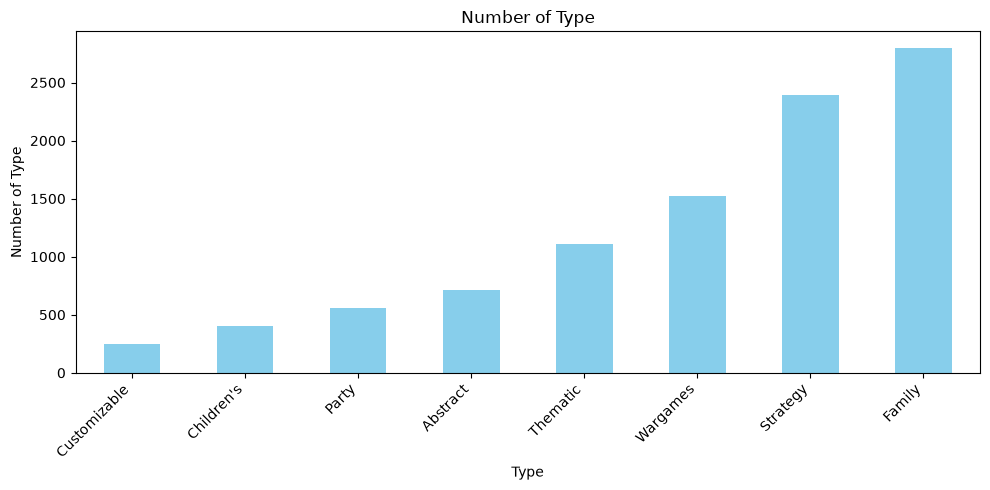

Customizable: 246
Children's: 404
Party: 561
Abstract: 709
Thematic: 1107
Wargames: 1519
Strategy: 2397
Family: 2801


In [15]:
#! show bar graph with the number of element for a type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, color="skyblue")

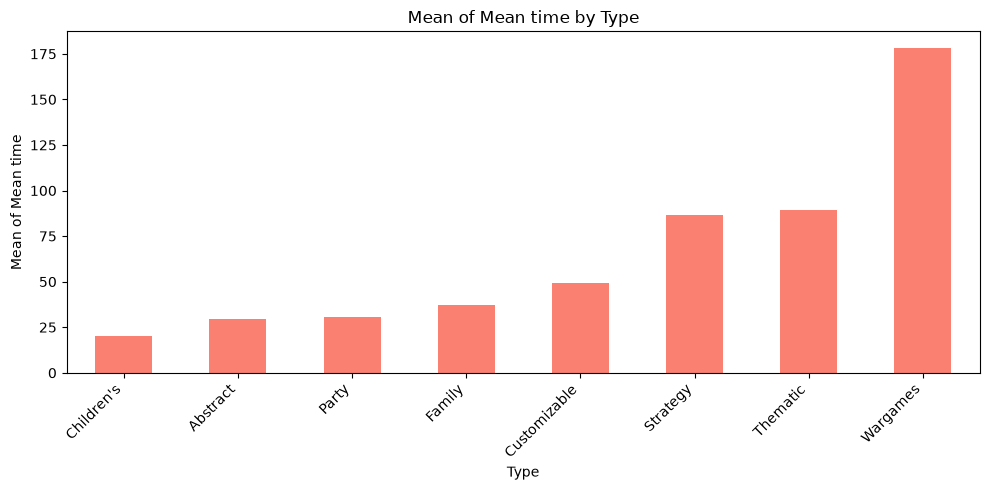

Children's: 20.28
Abstract: 29.29
Party: 30.48
Family: 37.23
Customizable: 49.18
Strategy: 86.70
Thematic: 89.16
Wargames: 178.43


In [16]:
#! show a bar graph with the mean time by type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, valueColumn=MEAN_TIME, agg_func='mean', color="salmon")

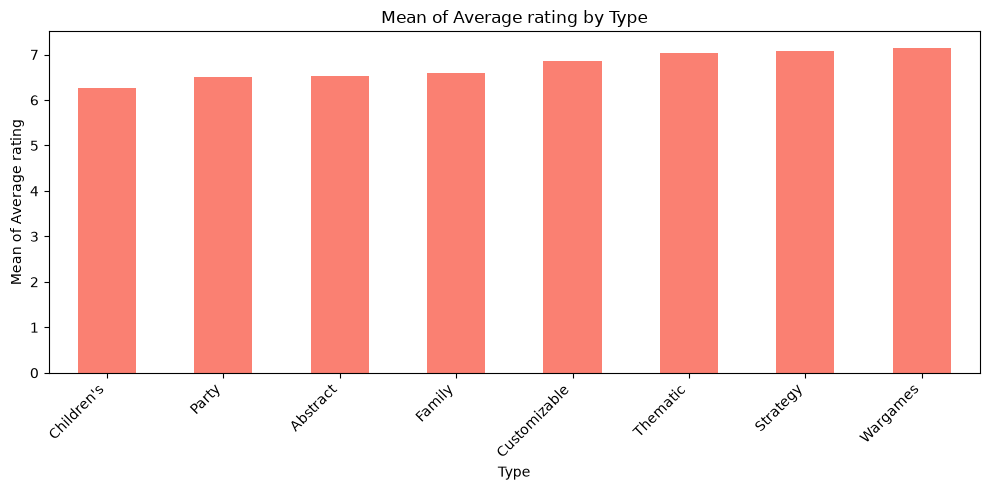

Children's: 6.26
Party: 6.51
Abstract: 6.53
Family: 6.59
Customizable: 6.86
Thematic: 7.04
Strategy: 7.07
Wargames: 7.15


In [17]:
#! mean of the rating by type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, valueColumn=AVERAGE_RATING, agg_func='mean', color="salmon")

# change dataset for deleting out of bound values

In [18]:
#! remove out of bound value
def remove_outliers_iqr(df, columns):
    # Supprime les valeurs aberrantes (en dehors de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]) 
    # pour les colonnes spécifiées dans un DataFrame.

    cleanerDataFrame = df.copy()
    
    for col in columns:
        Q1 = cleanerDataFrame[col].quantile(0.25)
        Q3 = cleanerDataFrame[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Filtrer les lignes
        cleanerDataFrame = cleanerDataFrame[
            (cleanerDataFrame[col] >= lower_bound) & 
            (cleanerDataFrame[col] <= upper_bound)
        ]
        
    return cleanerDataFrame

def remove_outliers_iqr_iterative(df, columns):
    cleanerDataFrame = df.copy()
    clean = False
    
    while not(clean):
        # Sauvegarde de la taille actuelle pour comparer après un tour
        previous_shape = cleanerDataFrame.shape
        
        # Application du nettoyage IQR
        cleanerDataFrame = remove_outliers_iqr(cleanerDataFrame, columns)
        
        # Si la taille n'a pas changé, le processus a convergé
        clean = cleanerDataFrame.shape == previous_shape
            
    return cleanerDataFrame

cleaner: 8560 87.85%
cleanest: 6941 71.23%


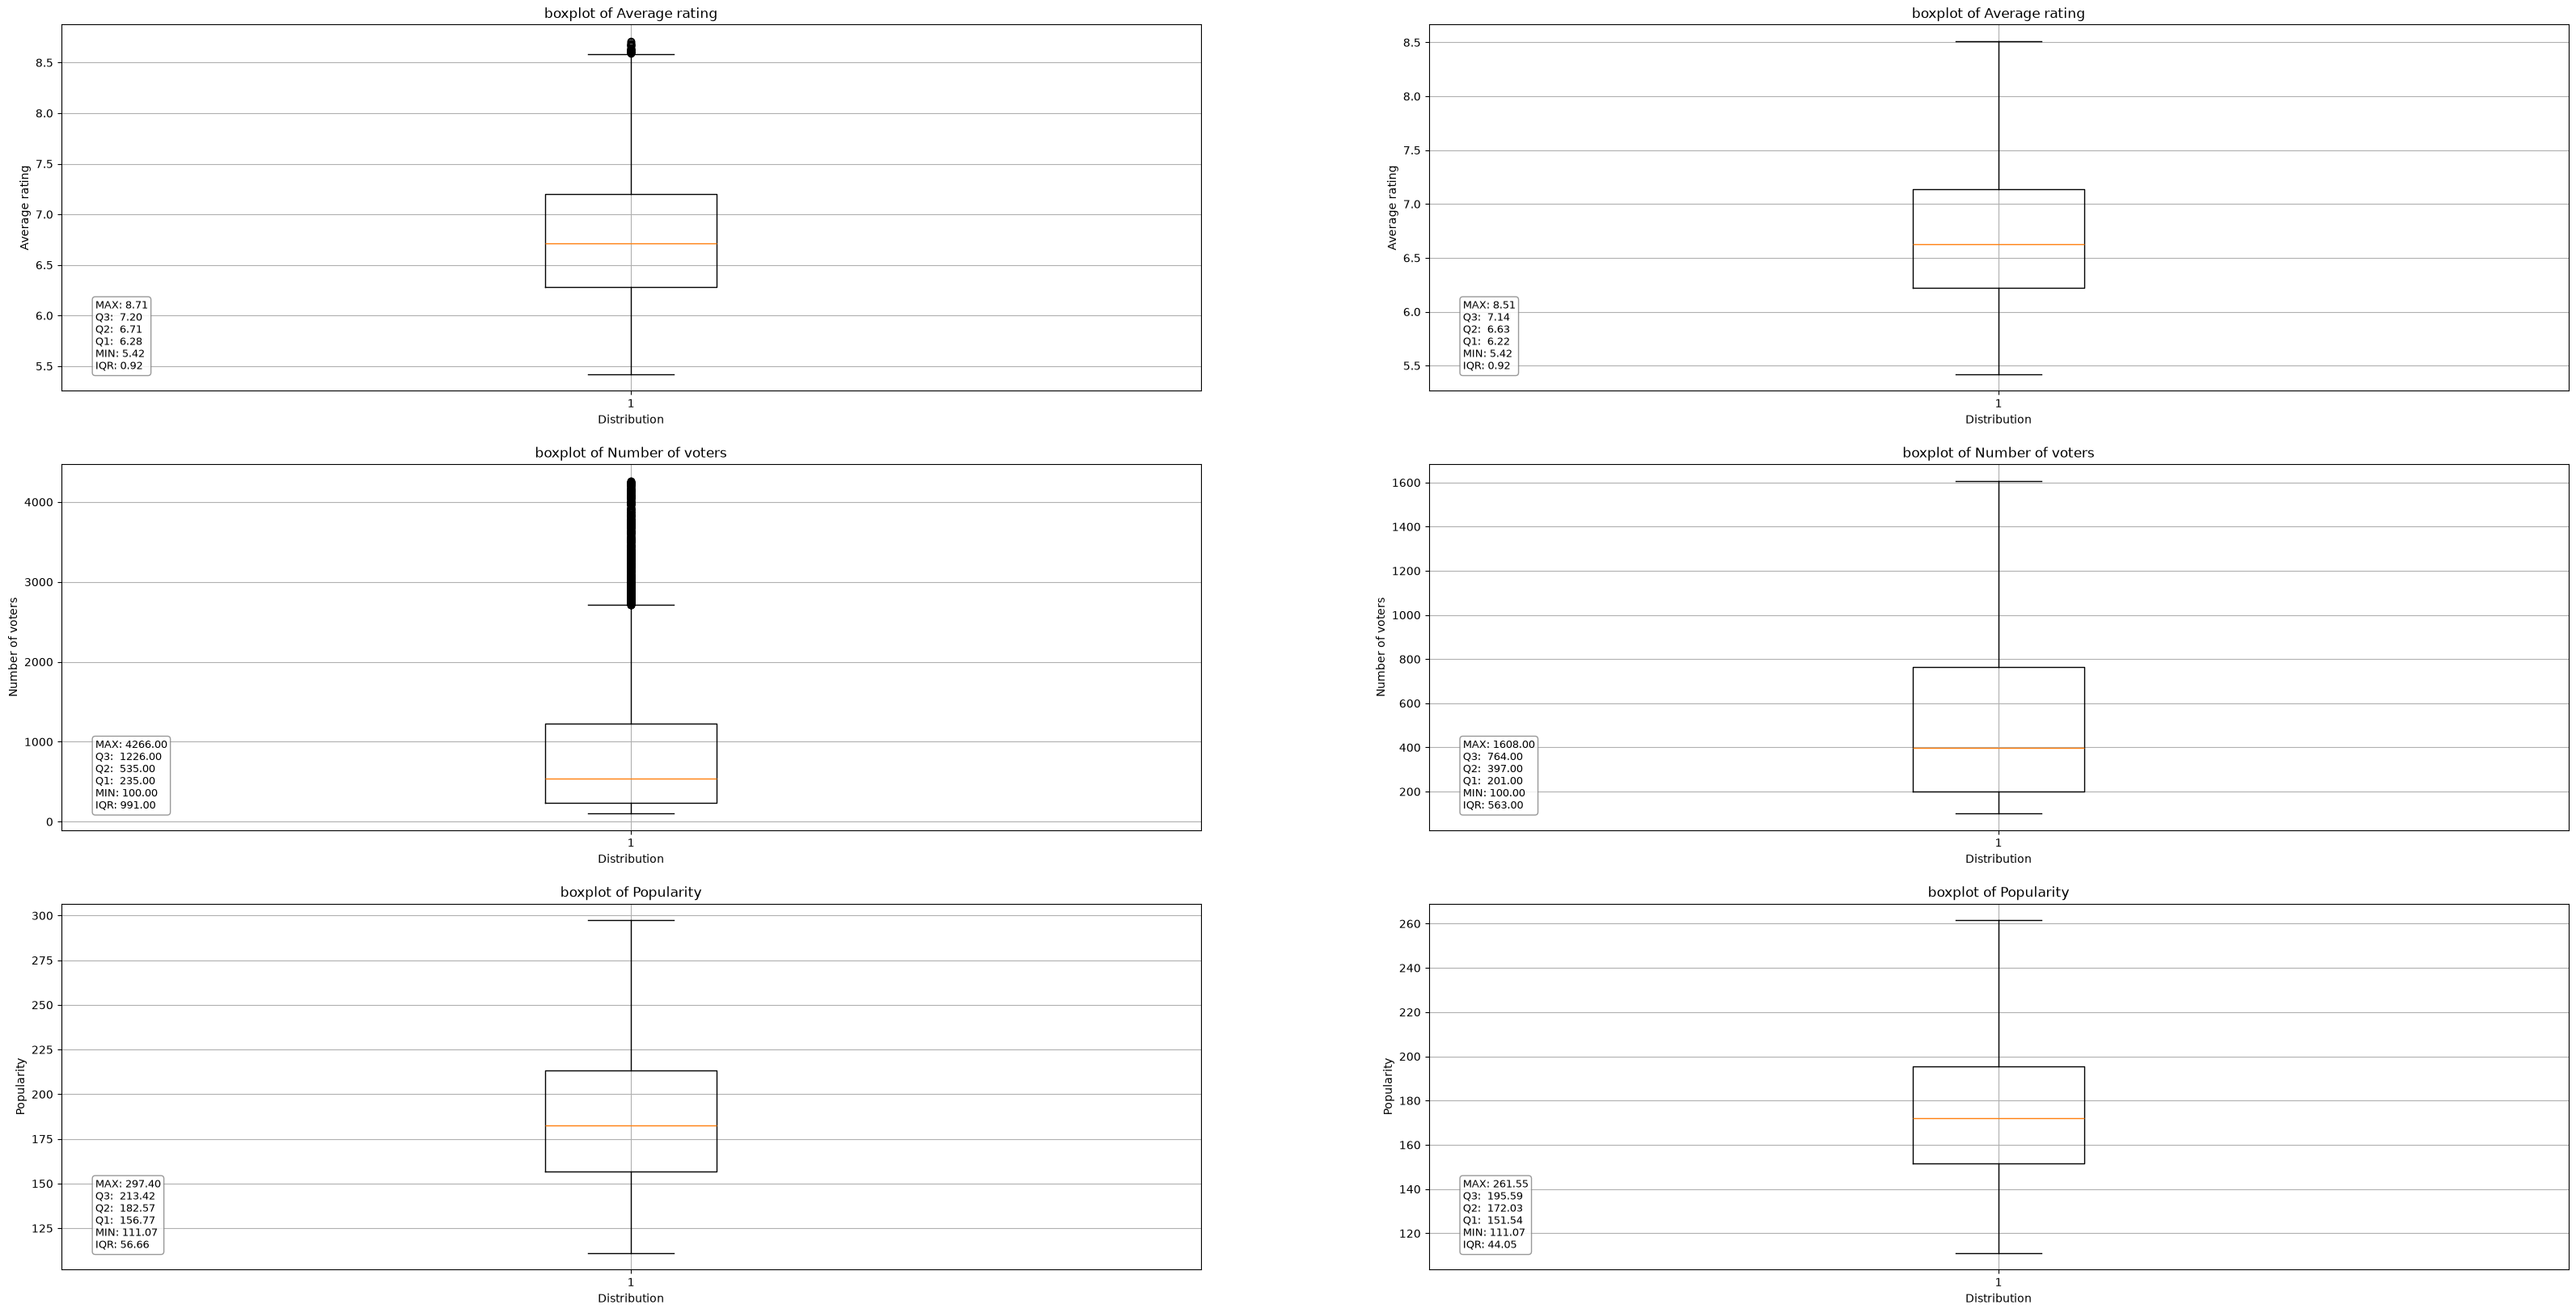

In [19]:
#! boxplot of rating, number of vote and popularity only with popular game

cleanerDataFrame = remove_outliers_iqr(cleanDataFrame, [AVERAGE_RATING, NUMBER_VOTE, POPULARITY])
cleanestDataFrame = remove_outliers_iqr_iterative(cleanDataFrame, [AVERAGE_RATING, NUMBER_VOTE, POPULARITY])

print(f"cleaner: {cleanerDataFrame.shape[0]} {round(cleanerDataFrame.shape[0]/cleanDataFrame.shape[0], 4)*100}%")
print(f"cleanest: {cleanestDataFrame.shape[0]} {round(cleanestDataFrame.shape[0]/cleanDataFrame.shape[0], 4)*100}%")

pyplot.figure(figsize=(40, 20))

pyplot.subplot(3, 2, 1)
boxplot(AVERAGE_RATING, whis=1.5, dataFrame=cleanerDataFrame)

pyplot.subplot(3, 2, 3)
boxplot(NUMBER_VOTE, whis=1.5, dataFrame=cleanerDataFrame)

pyplot.subplot(3, 2, 5)
boxplot(POPULARITY, whis=1.5, dataFrame=cleanerDataFrame)

pyplot.subplot(3, 2, 2)
boxplot(AVERAGE_RATING, whis=1.5, dataFrame=cleanestDataFrame)

pyplot.subplot(3, 2, 4)
boxplot(NUMBER_VOTE, whis=1.5, dataFrame=cleanestDataFrame)

pyplot.subplot(3, 2, 6)
boxplot(POPULARITY, whis=1.5, dataFrame=cleanestDataFrame)



pyplot.show()

# change dataset for popular only

In [20]:
#! remove popular game
popularDataFrame = cleanestDataFrame[cleanestDataFrame[POPULARITY] > cleanestDataFrame[POPULARITY].quantile(0.75)]
print(f"{popularDataFrame.shape[0]}\n{round(popularDataFrame.shape[0]/cleanestDataFrame.shape[0], 4)*100}%")
print(f"{round(popularDataFrame.shape[0]/cleanDataFrame.shape[0], 4)*100}%")

1734
24.98%
17.8%


In [21]:
# pandas.set_option('display.max_rows', None)
# pandas.set_option('display.max_columns', None)

popularDataFrame.sort_values(by=POPULARITY, ascending=True).reset_index(drop=True).head(popularDataFrame.shape[0])

,Title,Popularity,Average rating,Complexity,Min time,Max time,Min players,Max players,Number of voters,Type,Mean time
0,Pollen,195.60,7.01,2.00,30.0,45.0,2.0,4.0,616,Strategy,37.5
1,Rolling Freight,195.64,6.77,2.98,120.0,180.0,2.0,5.0,775,Strategy,150.0
2,Pluckin' Pairs,195.72,6.77,1.08,50.0,50.0,3.0,8.0,777,Party,50.0
3,Jenseits von Theben,195.72,7.13,2.42,75.0,75.0,2.0,4.0,555,Strategy,75.0
4,Monster Chase,195.72,6.31,1.02,10.0,10.0,1.0,6.0,1263,Children's,10.0
...,...,...,...,...,...,...,...,...,...,...,...
1729,Blood Bowl: Second Season Edition,259.28,8.50,3.77,60.0,180.0,2.0,2.0,1122,Strategy,120.0
1730,Chronicles of Drunagor: Age of Darkness,259.51,8.27,3.37,120.0,120.0,1.0,5.0,1373,Thematic,120.0
1731,Cosmic Encounter: 42nd Anniversary Edition,261.31,8.15,2.48,60.0,120.0,3.0,5.0,1607,Strategy,90.0
1732,Aeon's End: Outcasts,261.42,8.49,2.96,60.0,60.0,1.0,4.0,1199,Strategy,60.0


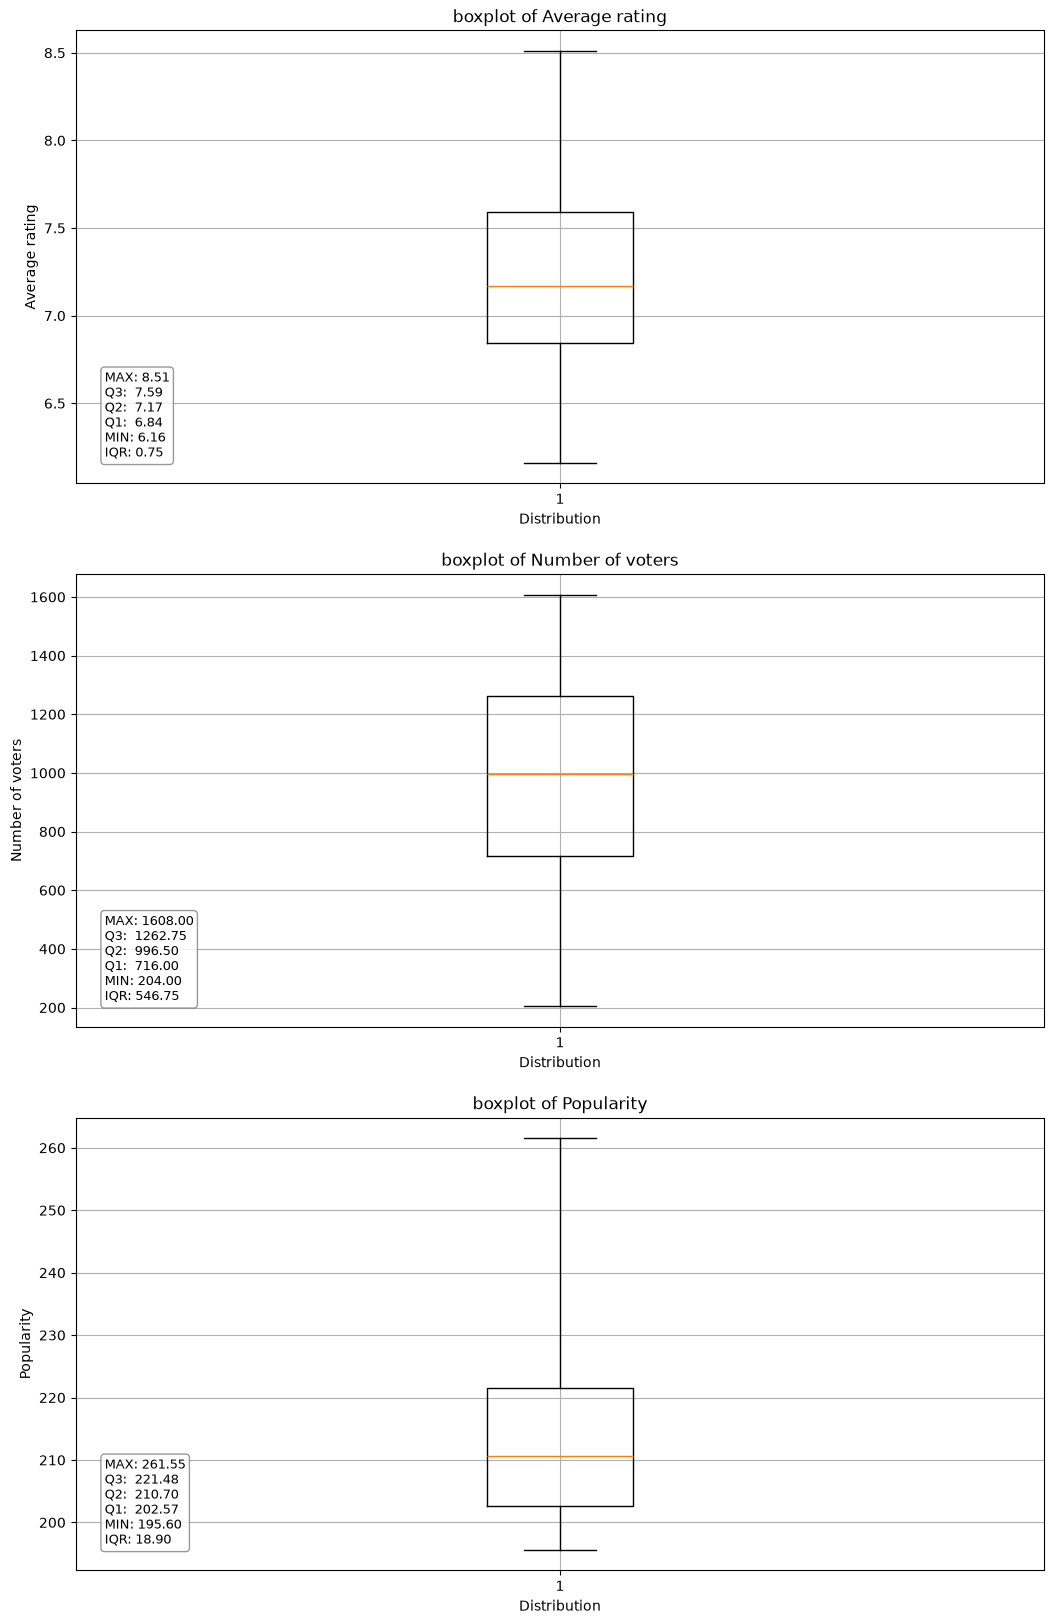

In [22]:
#! boxplot of rating, number of vote and popularity only with popular game
pyplot.figure(figsize=(12.5, 20))

pyplot.subplot(3, 1, 1)
boxplot(AVERAGE_RATING, dataFrame=popularDataFrame)

pyplot.subplot(3, 1, 2)
boxplot(NUMBER_VOTE, dataFrame=popularDataFrame)

pyplot.subplot(3, 1, 3)
boxplot(POPULARITY, dataFrame=popularDataFrame)



pyplot.show()